In [161]:
# Terry Chan # 1010156028
# Leon Qian #
# PHY224H1F 2024 Circuits Exercise - Diode
# Oct 6, 2024

In [162]:
import numpy as np
import pandas as pd
from uncertainties import unumpy as unp
from uncertainties import ufloat
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

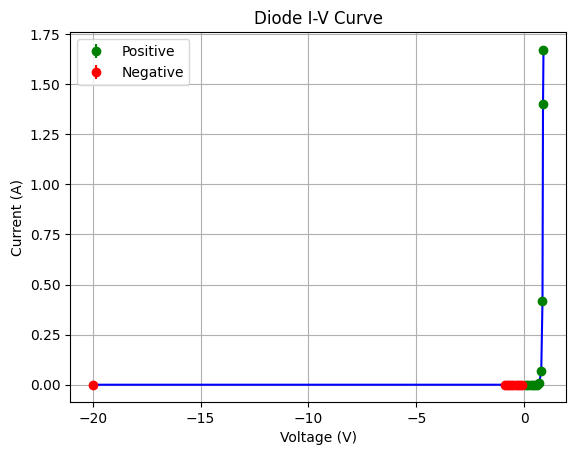

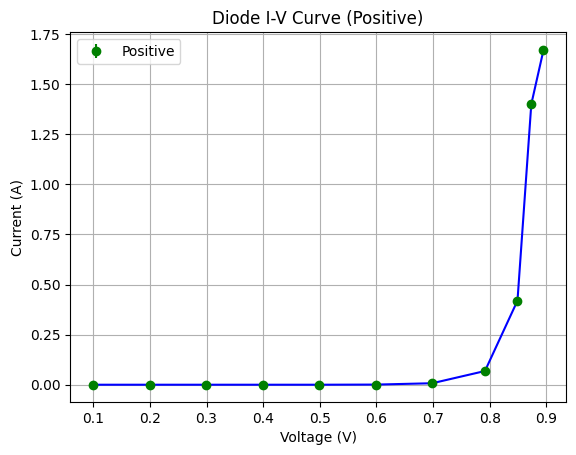

In [163]:
# Read data from the csv file
data_pos = pd.read_csv('Diode_positive.csv')
data_neg = pd.read_csv('Diode_negative.csv')

# Convert the data to numpy array
data_pos = data_pos.to_numpy()
data_neg = data_neg.to_numpy()

# Extract the data
V_pos = data_pos[:, 0]
I_pos = data_pos[:, 1]
V_neg = data_neg[:, 0]
I_neg = data_neg[:, 1] * 1e-6

# Convert the data to uncertainties array
I_pos = unp.uarray(I_pos, .3/100 * I_pos + 10 * .0001)
I_neg = unp.uarray(I_neg, .2/100 * I_neg + 5 * .01e-6)

# Combine the data
V = np.concatenate((V_neg, V_pos))
I = np.concatenate((I_neg, I_pos))

# Plot the data
plt.plot(V_pos, unp.nominal_values(I_pos), color='b')
plt.plot(V_neg, unp.nominal_values(I_neg), color='b')
plt.errorbar(V_pos, unp.nominal_values(I_pos), yerr=unp.std_devs(I_pos), fmt='go', label='Positive')
plt.errorbar(V_neg, unp.nominal_values(I_neg), yerr=unp.std_devs(I_neg), fmt='ro', label='Negative')
plt.xlabel('Voltage (V)')
plt.ylabel('Current (A)')
plt.title('Diode I-V Curve')
plt.legend()
plt.grid()
plt.savefig('I-V_Curve.png')
plt.show()

# Plot the positive data
plt.plot(V_pos, unp.nominal_values(I_pos), color='b')
plt.errorbar(V_pos, unp.nominal_values(I_pos), yerr=unp.std_devs(I_pos), fmt='go', label='Positive')
plt.xlabel('Voltage (V)')
plt.ylabel('Current (A)')
plt.title('Diode I-V Curve (Positive)')
plt.legend()
plt.grid()
plt.savefig('I-V_Curve_Positive.png')
plt.show()

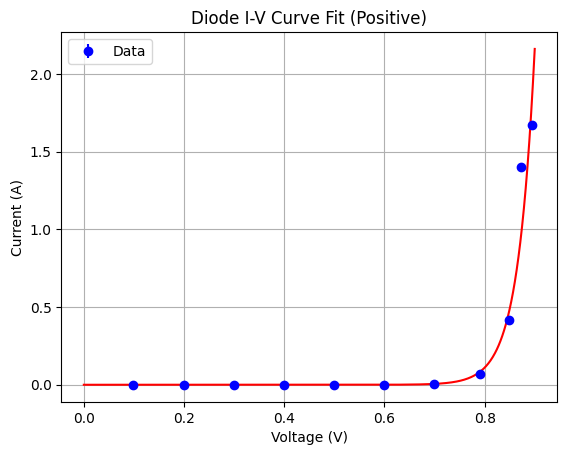

In [164]:
def diode_curve(V, Is, Vt):
    return Is * (np.exp(V / Vt) - 1)

# Fit the data
popt_pos, pcov_pos = curve_fit(diode_curve, V_pos, unp.nominal_values(I_pos), p0=[2e-6, 2/np.log(2)], sigma=unp.std_devs(I_pos), absolute_sigma=True)

# Plot the fit
V_fit = np.linspace(0, .9, 1000)
I_fit = diode_curve(V_fit, *popt_pos)
plt.plot(V_fit, I_fit, color='r')
plt.errorbar(V_pos, unp.nominal_values(I_pos), yerr=unp.std_devs(I_pos), fmt='bo', label='Data')
plt.xlabel('Voltage (V)')
plt.ylabel('Current (A)')
plt.title('Diode I-V Curve Fit (Positive)')
plt.legend()
plt.grid()
plt.savefig('I-V_Curve_Fit_Positive.png')
plt.show()

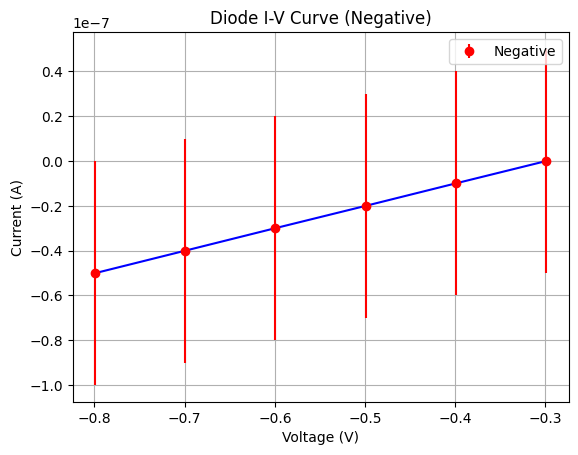

In [165]:
# Plot the negative data
plt.plot(V_neg[2:-2], unp.nominal_values(I_neg)[2:-2], color='b')
plt.errorbar(V_neg[2:-2], unp.nominal_values(I_neg)[2:-2], yerr=unp.std_devs(I_neg)[2:-2], fmt='ro', label='Negative')
plt.xlabel('Voltage (V)')
plt.ylabel('Current (A)')
plt.title('Diode I-V Curve (Negative)')
plt.legend()
plt.grid()
plt.savefig('I-V_Curve_Negative.png')
plt.show()

In [166]:
# Print the fit parameters
Is = ufloat(popt_pos[0], np.sqrt(pcov_pos[0, 0]))
Vt = ufloat(popt_pos[1], np.sqrt(pcov_pos[1, 1]))
print(f'Is = {Is:.2uP}')
print(f'Vt = {Vt:.2uP}')

Is = (5.04±0.44)×10⁻¹²
Vt = 0.03360±0.00011


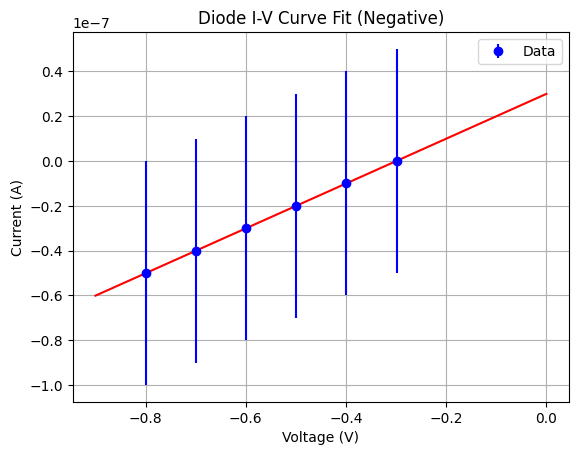

In [167]:
def linear_curve(V, m, b):
    return m * V + b

# Fit the data
popt_neg, pcov_neg = curve_fit(linear_curve, V_neg[2:-2], unp.nominal_values(I_neg)[2:-2], sigma=unp.std_devs(I_neg)[2:-2], absolute_sigma=True)

# Plot the fit
V_fit = np.linspace(-.9, 0, 1000)
I_fit = linear_curve(V_fit, *popt_neg)
plt.plot(V_fit, I_fit, color='r')
plt.errorbar(V_neg[2:-2], unp.nominal_values(I_neg)[2:-2], yerr=unp.std_devs(I_neg)[2:-2], fmt='bo', label='Data')
plt.xlabel('Voltage (V)')
plt.ylabel('Current (A)')
plt.title('Diode I-V Curve Fit (Negative)')
plt.legend()
plt.grid()
plt.savefig('I-V_Curve_Fit_Negative.png')
plt.show()

In [168]:
# Check if the fit predicts the data
expected = linear_curve(V_neg[-1], *popt_neg)
print(f'Expected = {expected:.2e} V')
print(f'Actual = {I_neg[-1]:.2uP} V')
# Print the fit parameters
m = ufloat(popt_neg[0], np.sqrt(pcov_neg[0, 0]))
b = ufloat(popt_neg[1], np.sqrt(pcov_neg[1, 1]))
print(f'm = {m:.2uP}')
print(f'b = {b:.2uP}')

Expected = -1.97e-06 V
Actual = (-1.960±0.046)×10⁻⁶ V
m = (1.0±1.2)×10⁻⁷
b = (3.0±6.9)×10⁻⁸
